In [8]:
pip install requests pandas matplotlib seaborn scikit-learn xgboost joblib streamlit

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached streamlit-1.66.0-py3-none-any.whl.metadata (10 kB)
  Using cached charset_normalizer-3.5.2-cp314-cp314-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached contourpy-1.4.0-

In [9]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


LAT, LON = -26.2041, 28.0473          # Johannesburg
START, END = "2022-07-01", "2026-09-25"

AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"
WX_URL = "https://archive-api.open-meteo.com/v1/archive"

def year_chunks(start, end):
    s, e = pd.Timestamp(start), pd.Timestamp(end)
    while s <= e:
        c_end = min(s + pd.DateOffset(years=1) - pd.Timedelta(days=1), e)
        yield s.strftime("%Y-%m-%d"), c_end.strftime("%Y-%m-%d")
        s = c_end + pd.Timedelta(days=1)

def fetch(url, hourly_vars, start, end):
    params = {
        "latitude": LAT, "longitude": LON,
        "hourly": ",".join(hourly_vars),
        "start_date": start, "end_date": end,
        "timezone": "Africa/Johannesburg",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    return pd.DataFrame(r.json()["hourly"])

aq, wx = [], []
for s, e in year_chunks(START, END):
    aq.append(fetch(AQ_URL, ["pm2_5", "pm10", "nitrogen_dioxide", "ozone"], s, e))
    wx.append(fetch(WX_URL, ["temperature_2m", "relative_humidity_2m",
                             "wind_speed_10m", "precipitation", "surface_pressure"], s, e))

aq = pd.concat(aq); wx = pd.concat(wx)
df = aq.merge(wx, on="time")
df["time"] = pd.to_datetime(df["time"])

daily = df.set_index("time").resample("D").mean().reset_index()
daily.to_csv("johannesburg_air_quality.csv", index=False)
print(daily.head(), len(daily))

        time  pm2_5  pm10  nitrogen_dioxide  ozone  temperature_2m  \
0 2022-07-01    NaN   NaN               NaN    NaN        7.687500   
1 2022-07-02    NaN   NaN               NaN    NaN        8.158333   
2 2022-07-03    NaN   NaN               NaN    NaN        9.450000   
3 2022-07-04    NaN   NaN               NaN    NaN        9.845833   
4 2022-07-05    NaN   NaN               NaN    NaN       12.370833   

   relative_humidity_2m  wind_speed_10m  precipitation  surface_pressure  
0             58.375000        8.025000            0.0        834.537500  
1             57.333333        9.441667            0.0        833.462500  
2             58.291667       10.212500            0.0        833.516667  
3             56.958333        7.604167            0.0        834.104167  
4             50.500000        9.962500            0.0        834.108333   1548


In [10]:
df = pd.read_csv("johannesburg_air_quality.csv", parse_dates=["time"])
print(df.shape)
df.info()
print(df.isna().sum())

(1548, 10)
<class 'pandas.DataFrame'>
RangeIndex: 1548 entries, 0 to 1547
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  1548 non-null   datetime64[us]
 1   pm2_5                 1514 non-null   float64       
 2   pm10                  1514 non-null   float64       
 3   nitrogen_dioxide      1514 non-null   float64       
 4   ozone                 1514 non-null   float64       
 5   temperature_2m        1548 non-null   float64       
 6   relative_humidity_2m  1548 non-null   float64       
 7   wind_speed_10m        1548 non-null   float64       
 8   precipitation         1548 non-null   float64       
 9   surface_pressure      1548 non-null   float64       
dtypes: datetime64[us](1), float64(9)
memory usage: 121.1 KB
time                     0
pm2_5                   34
pm10                    34
nitrogen_dioxide        34
ozone                   34
t

In [11]:
first_valid = df["pm2_5"].first_valid_index()
print("Air quality data starts on:", df.loc[first_valid, "time"])

data = df.loc[first_valid:].reset_index(drop=True)
print(data.shape)
print(data.isna().sum())
print(data.describe())

Air quality data starts on: 2022-08-04 00:00:00
(1514, 10)
time                    0
pm2_5                   0
pm10                    0
nitrogen_dioxide        0
ozone                   0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
precipitation           0
surface_pressure        0
dtype: int64
                      time        pm2_5         pm10  nitrogen_dioxide  \
count                 1514  1514.000000  1514.000000       1514.000000   
mean   2024-08-29 12:00:00    30.337899    36.737443         31.520167   
min    2022-08-04 00:00:00     0.945833     1.383333          0.000000   
25%    2023-08-17 06:00:00    18.223958    22.542708         19.846875   
50%    2024-08-29 12:00:00    25.308333    31.641667         27.435417   
75%    2025-09-11 18:00:00    37.028125    45.313542         41.104167   
max    2026-09-25 00:00:00   182.220833   185.116667        108.229167   
std                    NaN    18.539358    20.658719         14.963792   

 

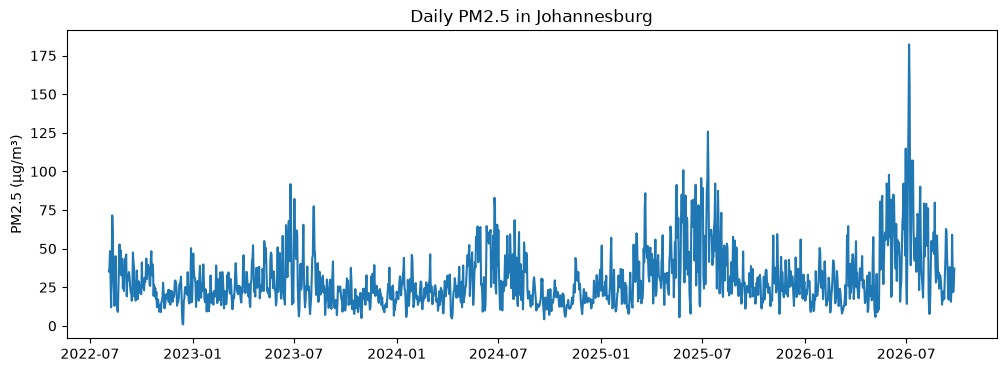

In [12]:
plt.figure(figsize=(12, 4))
plt.plot(data["time"], data["pm2_5"])
plt.title("Daily PM2.5 in Johannesburg")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

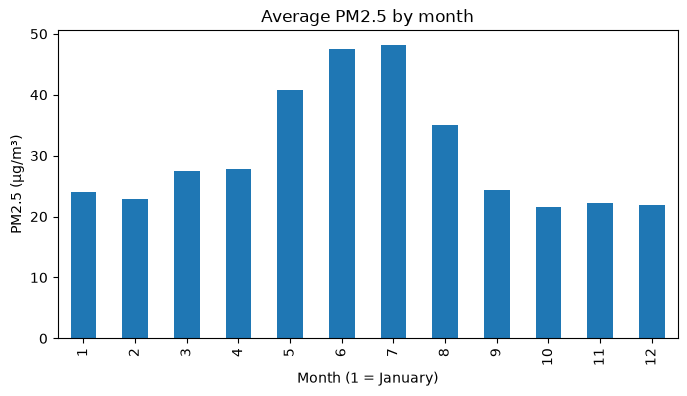

In [13]:
data["month"] = data["time"].dt.month
data.groupby("month")["pm2_5"].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Average PM2.5 by month")
plt.xlabel("Month (1 = January)")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

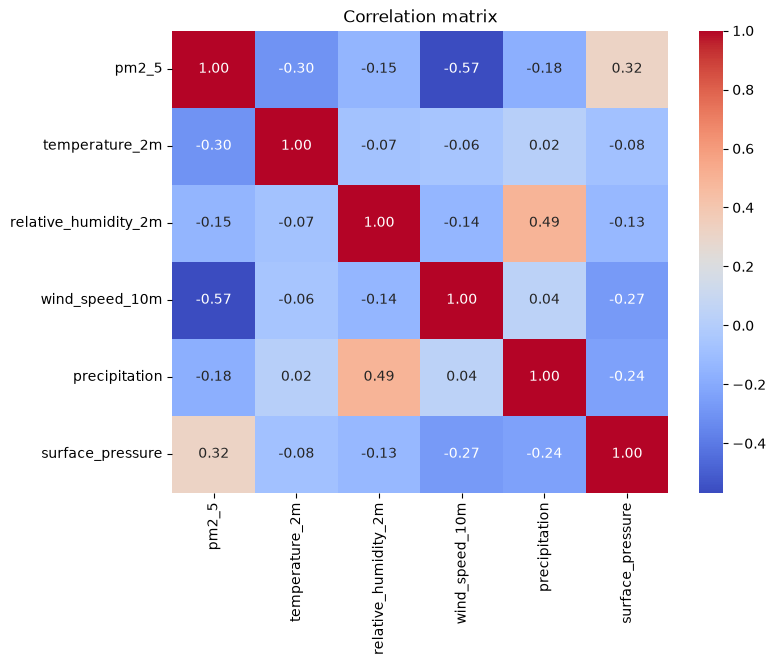

In [14]:
cols = ["pm2_5", "temperature_2m", "relative_humidity_2m",
        "wind_speed_10m", "precipitation", "surface_pressure"]
plt.figure(figsize=(8, 6))
sns.heatmap(data[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

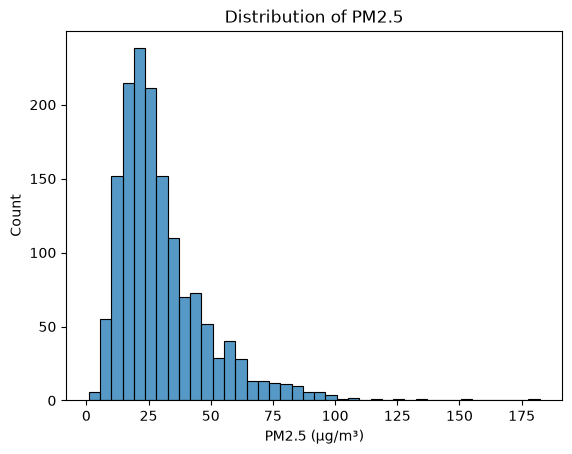

In [15]:
sns.histplot(data["pm2_5"].dropna(), bins=40)
plt.title("Distribution of PM2.5")
plt.xlabel("PM2.5 (µg/m³)")
plt.show()

In [16]:
print(data.shape)   # should show 1514 rows

data["rain_day"] = data["precipitation"] > 0
print(data.groupby("rain_day")["pm2_5"].agg(["count", "mean", "median"]))

(1514, 11)
          count       mean     median
rain_day                             
False       859  34.184861  28.533333
True        655  25.292799  23.100000


In [17]:
print(data["pm2_5"].corr(data["pm2_5"].shift(-1)))

0.6906871370654967


In [18]:
data["month"] = data["time"].dt.month    # safe to repeat

features = ["pm2_5", "pm10", "nitrogen_dioxide", "ozone",
            "temperature_2m", "relative_humidity_2m",
            "wind_speed_10m", "precipitation", "surface_pressure", "month"]

model_data = data[["time"] + features].copy()
model_data["target"] = model_data["pm2_5"].shift(-1)       # tomorrow's PM2.5
model_data = model_data.dropna().reset_index(drop=True)    # last day has no "tomorrow"

split = int(len(model_data) * 0.8)
train = model_data.iloc[:split]
test = model_data.iloc[split:]

X_train, y_train = train[features], train["target"]
X_test, y_test = test[features], test["target"]

print("Total rows:", len(model_data))
print("Train:", len(train), "|", train["time"].min().date(), "to", train["time"].max().date())
print("Test: ", len(test), "|", test["time"].min().date(), "to", test["time"].max().date())
print(model_data[["time", "pm2_5", "target"]].head())

Total rows: 1513
Train: 1210 | 2022-08-04 to 2025-11-25
Test:  303 | 2025-11-26 to 2026-09-24
        time      pm2_5     target
0 2022-08-04  35.250000  37.395833
1 2022-08-05  37.395833  48.350000
2 2022-08-06  48.350000  28.762500
3 2022-08-07  28.762500  11.958333
4 2022-08-08  11.958333  37.712500


In [19]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2)}

results = []
predictions = {}

# 1. Baseline: tomorrow = today
predictions["Baseline"] = X_test["pm2_5"]
results.append(evaluate("Baseline (tomorrow = today)", y_test, predictions["Baseline"]))

# 2. Linear regression
lr = LinearRegression().fit(X_train, y_train)
predictions["Linear Regression"] = lr.predict(X_test)
results.append(evaluate("Linear Regression", y_test, predictions["Linear Regression"]))

# 3. Random Forest
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                           random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
predictions["Random Forest"] = rf.predict(X_test)
results.append(evaluate("Random Forest", y_test, predictions["Random Forest"]))

results_df = pd.DataFrame(results)
print(results_df)

print("\nHighest PM2.5 in train:", round(y_train.max(), 1))
print("Highest PM2.5 in test: ", round(y_test.max(), 1))

                         Model    MAE   RMSE
0  Baseline (tomorrow = today)  13.34  19.04
1            Linear Regression  11.68  16.48
2                Random Forest  12.05  18.41

Highest PM2.5 in train: 125.7
Highest PM2.5 in test:  182.2


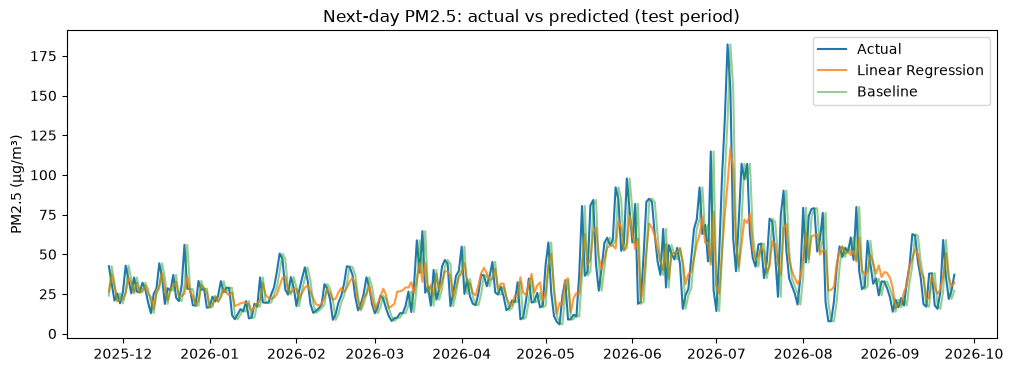

In [20]:
plt.figure(figsize=(12, 4))
plt.plot(test["time"], y_test.values, label="Actual", linewidth=1.5)
plt.plot(test["time"], predictions["Linear Regression"], label="Linear Regression", alpha=0.8)
plt.plot(test["time"], predictions["Baseline"].values, label="Baseline", alpha=0.5)
plt.title("Next-day PM2.5: actual vs predicted (test period)")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

In [21]:
import joblib

bundle = {
    "model": lr,
    "features": features,
    "test_mae": float(mean_absolute_error(y_test, predictions["Linear Regression"])),
}
joblib.dump(bundle, "airsense_model.joblib")
print("Saved. Typical error (MAE):", round(bundle["test_mae"], 2))

Saved. Typical error (MAE): 11.68


In [22]:
demo = pd.DataFrame({
    "date_to_pick_in_app": test["time"].dt.date.values,
    "actual_tomorrow": y_test.values.round(1),
    "predicted_tomorrow": predictions["Linear Regression"].round(1),
})
demo["abs_error"] = (demo["predicted_tomorrow"] - demo["actual_tomorrow"]).abs().round(1)

cuts = [0, 15, 35, 55, 150, 1000]
names = ["Good", "Moderate", "Unhealthy for sensitive groups", "Unhealthy", "Very unhealthy"]
demo["actual_band"] = pd.cut(demo["actual_tomorrow"], bins=cuts, labels=names)

print("Closest predictions in each band:")
for name in names:
    sub = demo[demo["actual_band"] == name].nsmallest(2, "abs_error")
    print("\n" + name)
    print(sub.drop(columns="actual_band").to_string(index=False))

print("\nBiggest misses:")
print(demo.nlargest(3, "abs_error").drop(columns="actual_band").to_string(index=False))

Closest predictions in each band:

Good
date_to_pick_in_app  actual_tomorrow  predicted_tomorrow  abs_error
         2026-03-01             12.8                15.0        2.2
         2026-01-16             10.3                14.2        3.9

Moderate
date_to_pick_in_app  actual_tomorrow  predicted_tomorrow  abs_error
         2026-01-01             16.9                16.7        0.2
         2026-02-12             28.4                28.2        0.2

Unhealthy for sensitive groups
date_to_pick_in_app  actual_tomorrow  predicted_tomorrow  abs_error
         2026-08-17             51.3                51.6        0.3
         2026-06-15             50.1                50.5        0.4

Unhealthy
date_to_pick_in_app  actual_tomorrow  predicted_tomorrow  abs_error
         2026-06-09             62.0                61.8        0.2
         2026-05-24             55.8                55.4        0.4

Very unhealthy
date_to_pick_in_app  actual_tomorrow  predicted_tomorrow  abs_error
       